In [1]:
import numpy as np
import matplotlab.pyplot as plt

from PIL import image
from scipy import ndimage

ModuleNotFoundError: No module named 'numpy'

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from scipy import ndimage

In [3]:
image = Image.open("MyImg.jpeg")

print("Image mode:", image.mode)
print("Image size:", image.size)

Image mode: RGB
Image size: (1200, 1600)


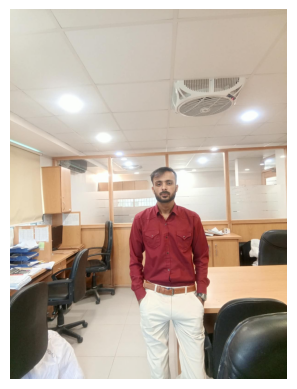

In [4]:
plt.imshow(image)
plt.axis("off")
plt.show()

In [5]:
gray_image = image.convert("L")

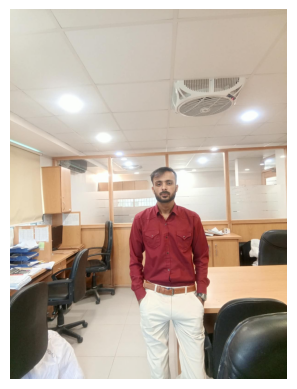

In [6]:
plt.imshow(image)
plt.axis("off")
plt.show()

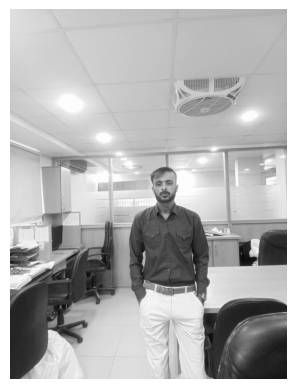

In [7]:
plt.imshow(gray_image, cmap="gray")
plt.axis("off")
plt.show()

In [8]:
gray_array = np.array(gray_image)

In [9]:
print("Array shape:", gray_array.shape)
print("Data type:", gray_array.dtype)

Array shape: (1600, 1200)
Data type: uint8


In [10]:
print(gray_array[:5, :5])

[[224 224 224 224 224]
 [224 224 224 224 224]
 [224 224 224 224 224]
 [224 224 224 224 224]
 [224 224 224 224 224]]


In [11]:
average_kernel = np.array([
    [1, 1, 1],
    [1, 1, 1],
    [1, 1, 1]
])

print(average_kernel)

[[1 1 1]
 [1 1 1]
 [1 1 1]]


In [12]:
average_filtered = ndimage.convolve(
    gray_array,
    average_kernel,
    mode="constant",
    cval=0
)

In [13]:
average_filtered = average_filtered / 9

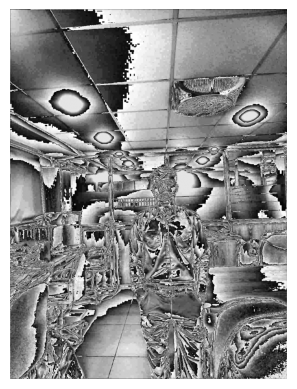

In [14]:
plt.imshow(average_filtered, cmap="gray")
plt.axis("off")
plt.show()

In [15]:
print("Minimum:", average_filtered.min())
print("Maximum:", average_filtered.max())
print("Data type:", average_filtered.dtype)

Minimum: 0.0
Maximum: 28.333333333333332
Data type: float64


In [16]:
print(average_filtered[:5, :5])

[[14.22222222  7.11111111  7.11111111  7.11111111  7.11111111]
 [ 7.11111111 24.88888889 24.88888889 24.88888889 24.88888889]
 [ 7.11111111 24.88888889 24.88888889 24.88888889 24.88888889]
 [ 7.11111111 24.88888889 24.88888889 24.88888889 24.88888889]
 [ 7.11111111 24.88888889 24.88888889 24.88888889 24.88888889]]


In [17]:
gray_array_float = gray_array.astype(np.float32)

print("Data type:", gray_array_float.dtype)

Data type: float32


In [18]:
average_filtered = ndimage.convolve(
    gray_array_float,
    average_kernel,
    mode="constant",
    cval=0
)

average_filtered = average_filtered / 9

In [19]:
print("Minimum:", average_filtered.min())
print("Maximum:", average_filtered.max())
print("Data type:", average_filtered.dtype)
print(average_filtered[:5, :5])

Minimum: 5.111111
Maximum: 254.88889
Data type: float32
[[ 99.55556 149.33333 149.33333 149.33333 149.33333]
 [149.33333 224.      224.      224.      224.     ]
 [149.33333 224.      224.      224.      224.     ]
 [149.33333 224.      224.      224.      224.     ]
 [149.33333 224.      224.      224.      224.     ]]


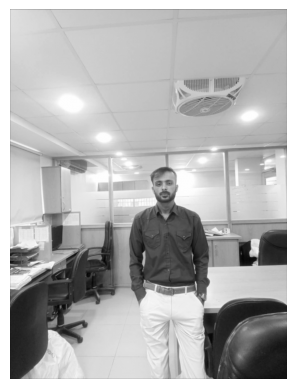

In [20]:
plt.imshow(average_filtered, cmap="gray")
plt.axis("off")
plt.show()

In [21]:
weighted_kernel = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
])

In [22]:
print("Kernel sum:", weighted_kernel.sum())

Kernel sum: 16


In [23]:
weighted_filtered = ndimage.convolve(
    gray_array_float,
    weighted_kernel,
    mode="constant",
    cval=0
)

weighted_filtered = weighted_filtered / weighted_kernel.sum()

In [24]:
print("Minimum:", weighted_filtered.min())
print("Maximum:", weighted_filtered.max())
print("Data type:", weighted_filtered.dtype)
print(weighted_filtered[:5, :5])

Minimum: 5.0625
Maximum: 254.9375
Data type: float64
[[126. 168. 168. 168. 168.]
 [168. 224. 224. 224. 224.]
 [168. 224. 224. 224. 224.]
 [168. 224. 224. 224. 224.]
 [168. 224. 224. 224. 224.]]


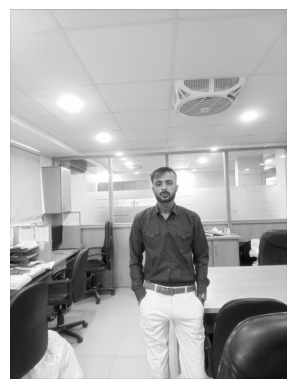

In [25]:
plt.imshow(weighted_filtered, cmap="gray")
plt.axis("off")
plt.show()

In [26]:
laplacian_kernel = np.array([
    [0, 1, 0],
    [1, -4, 1],
    [0, 1, 0]
])

In [27]:
laplacian_filtered = ndimage.convolve(
    gray_array_float,
    laplacian_kernel,
    mode="constant",
    cval=0
)

In [28]:
print("Minimum:", laplacian_filtered.min())
print("Maximum:", laplacian_filtered.max())
print("Data type:", laplacian_filtered.dtype)

Minimum: -448.0
Maximum: 262.0
Data type: float32


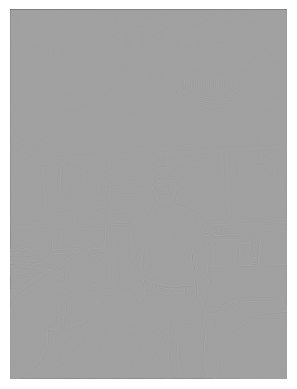

In [29]:
plt.imshow(laplacian_filtered, cmap="gray")
plt.axis("off")
plt.show()


In [30]:
laplacian_filtered = ndimage.convolve(
    gray_array_float,
    laplacian_kernel,
    mode="reflect"
)

In [31]:
print("Minimum:", laplacian_filtered.min())
print("Maximum:", laplacian_filtered.max())
print("Data type:", laplacian_filtered.dtype)

Minimum: -315.0
Maximum: 262.0
Data type: float32


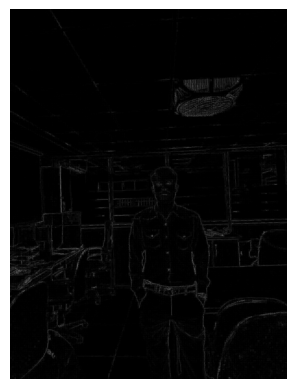

In [32]:
laplacian_display = np.abs(laplacian_filtered)

plt.imshow(laplacian_display, cmap="gray")
plt.axis("off")
plt.show()